# Volatility Forecasting — SPY Multi-Model Engine

**Research question:** Can ML models reliably outperform GARCH(1,1) for next-day realized volatility forecasting?

**Approach:** Expanding-window GARCH(1,1)-t baseline → GMM regime detection → fractional differentiation (López de Prado 2018) → XGBoost, LightGBM, monotone-constrained XGBoost, stacking ensemble + Huber meta-learner (Sovereign Prime).

**Evaluation:** Strict 80/20 chronological split. QLIKE primary; RMSE and MAPE secondary.

**Key finding:** GARCH is a formidable benchmark. ML gains are modest in QLIKE. Monotone constraints on the leverage effect (Entropy model) offer the best interpretability–performance tradeoff. Huber meta-learner is robust to vol-spike outliers.

## 0. Imports & Configuration

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path
from scipy.optimize import minimize
from scipy import stats
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import HuberRegressor, RidgeCV
from sklearn.isotonic import IsotonicRegression
from arch import arch_model
import xgboost as xgb
import lightgbm as lgb
import joblib

# ── Project modules ────────────────────────────────────────────────────────
import sys
sys.path.insert(0, str(Path.cwd() / 'src'))
from metrics import rmse, mae, qlike, mape, report
from opendata import fred, french  # FRED + Ken French open data, no Yahoo
from models import constrained_weights, get_monotone_constraints
from feature_engineering import (
    frac_diff_vec, find_min_d,
    build_lookback_windows, walk_forward_cv, make_oof_predictions,
)

# ── Constants ──────────────────────────────────────────────────────────────
SEED       = 42
LOOKBACK   = 20    # 1 trading month
TEST_FRAC  = 0.20
EMBARGO    = 5     # gap = 5-day RV target horizon
BURNIN     = 252   # min obs before first GARCH fit
REFIT_FREQ = 21    # monthly GARCH refit
MODEL_DIR  = Path('../models'); MODEL_DIR.mkdir(exist_ok=True)

np.random.seed(SEED)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 120, 'savefig.bbox': 'tight'})

## 1. Data Loading

SPY daily OHLCV (2014–2024). Three complementary volatility estimators:
- **Garman-Klass**: OHLC estimator, ~7× lower variance than close-to-close
- **Parkinson**: range-only — intraday stress proxy
- **Overnight gap**: `|ln(Open_t / Close_{t-1})|` — event risk

2762 trading days  |  2014-01-09 → 2024-12-30


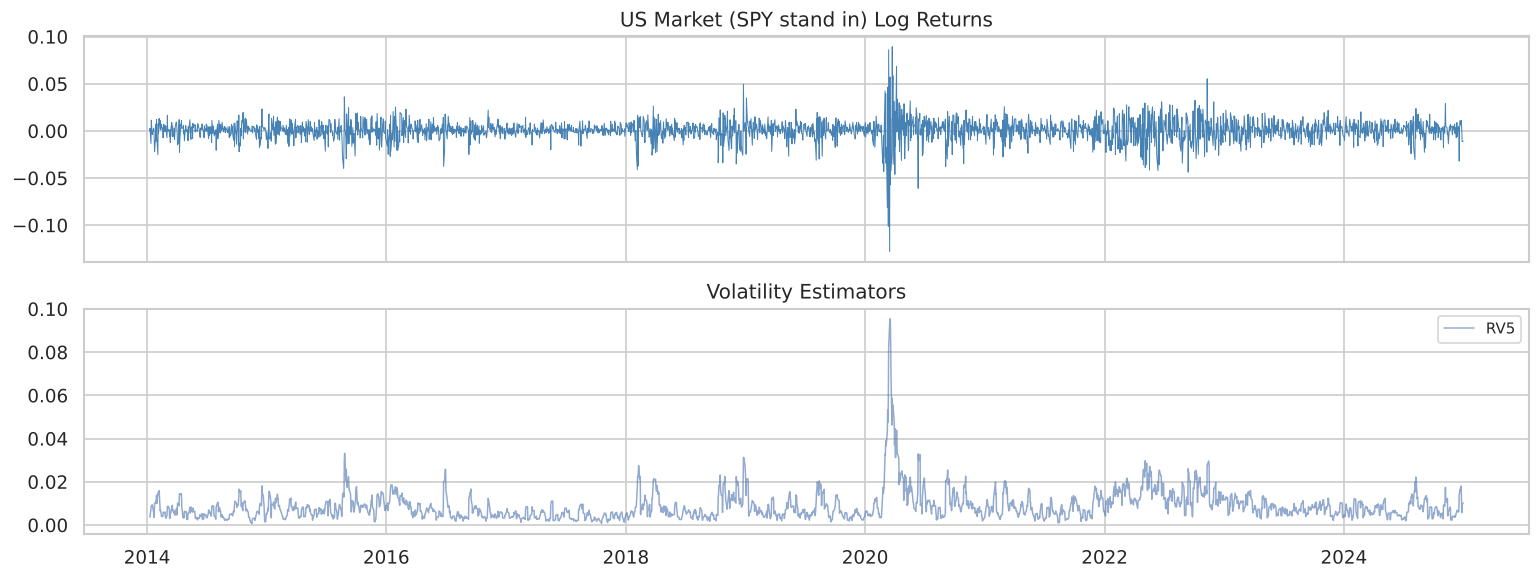

In [2]:
# SPY stand in: Ken French US market total return (Mkt-RF + RF) as an index.
# Open sources give closes only, so the OHLC estimators (Garman-Klass,
# Parkinson, overnight gap) from the earlier Yahoo version are not available.
_ff  = french('F-F_Research_Data_Factors_daily', start='2014-01-01', end='2024-12-31')
raw  = pd.DataFrame({'Close': 100 * (1 + _ff['Mkt-RF'] + _ff['RF']).cumprod()})

raw['Log_Ret'] = np.log(raw['Close'] / raw['Close'].shift(1))

# RV5: contemporaneous feature; Target_RV5: next-day (forecast target)
raw['RV5']       = raw['Log_Ret'].rolling(5).std()
raw['Target_RV5'] = raw['RV5'].shift(-1)
raw.dropna(inplace=True)

print(f"{raw.shape[0]} trading days  |  {raw.index[0].date()} → {raw.index[-1].date()}")

fig, axes = plt.subplots(2, 1, figsize=(13, 5), sharex=True)
axes[0].plot(raw['Log_Ret'], lw=0.6, color='steelblue')
axes[0].set_title('US Market (SPY stand in) Log Returns')
axes[1].plot(raw['RV5'],    lw=0.9, alpha=0.6, label='RV5')
axes[1].set_title('Volatility Estimators'); axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

## 2. Expanding-Window GARCH(1,1)-t Baseline

GARCH is fitted on an expanding window and refitted monthly.  
**Leakage fix:** the feature for day *t* is σ̂_{t|t-1} (yesterday's forecast), achieved via `shift(1)` on the conditional volatility series. Using σ̂_t (same-day) would incorporate ε_t — a look-ahead bias.

In [3]:
returns_pct = raw['Log_Ret'].dropna() * 100
garch_vol   = pd.Series(np.nan, index=returns_pct.index)

fit_indices = list(range(BURNIN, len(returns_pct), REFIT_FREQ))
if fit_indices[-1] != len(returns_pct) - 1:
    fit_indices.append(len(returns_pct) - 1)

res_cache, prev_end = None, BURNIN
for end_idx in fit_indices:
    try:
        res_cache = arch_model(returns_pct.iloc[:end_idx],
                               vol='Garch', p=1, q=1, dist='t'
                               ).fit(disp='off', show_warning=False)
    except Exception:
        pass
    if res_cache is not None:
        cv = res_cache.conditional_volatility / 100
        seg_dates = returns_pct.index[prev_end:end_idx]
        s, e = max(0, prev_end - 1), end_idx - 1   # shift(-1): yesterday's forecast
        if len(seg_dates) > 0 and len(cv) > e:
            garch_vol[seg_dates[:e - s]] = cv.iloc[s:e].values
    prev_end = end_idx

raw['GARCH_Vol'] = garch_vol
raw.dropna(subset=['GARCH_Vol'], inplace=True)
print(f"GARCH complete. Shape: {raw.shape}")

GARCH complete. Shape: (2509, 5)


## 3. Feature Engineering

**Macro features:** VIX (implied vol), RSI, Bollinger Band Width, VRP signal, return momentum, realised skewness, vol-of-vol, Baa-Treasury credit spread (FRED BAA10Y).  
**Fractional differentiation** (López de Prado 2018): minimum *d* that achieves stationarity while preserving maximum memory. Grid starts at 0.1 — *d*=0 returns non-stationary log-price.

In [4]:
# ── Implied vol ────────────────────────────────────────────────────────────
vix = fred('VIXCLS', '2014-01-01', '2024-12-31').rename(columns={'VIXCLS': 'Close'}).dropna()
raw = raw.join(vix['Close'].rename('VIX'), how='inner')

# ── Price-based signals ────────────────────────────────────────────────────
delta = raw['Close'].diff()
gain, loss = delta.clip(lower=0).rolling(14).mean(), (-delta.clip(upper=0)).rolling(14).mean()
raw['RSI']       = (100 - 100 / (1 + gain / loss.replace(0, np.nan))).clip(0, 100)
raw['BB_Width']  = 4 * raw['Close'].rolling(20).std()   # = 2*(upper - lower)
raw['Return_Mom'] = raw['Log_Ret'].rolling(5).mean()
raw['Skewness']  = raw['Log_Ret'].rolling(60).skew()
raw['Vol_of_Vol'] = raw['RV5'].rolling(20).std()   # close-to-close (no OHLC in open data)

# ── Cross-asset signals ────────────────────────────────────────────────────
raw['VIX_Daily']  = raw['VIX'] / (100 * np.sqrt(252))   # annualised % → daily decimal
raw['VRP_Signal'] = raw['GARCH_Vol'] - raw['VIX_Daily']  # +ve: GARCH > implied → buy vol

# Credit stress: Moody's Baa minus 10y Treasury spread (FRED BAA10Y), rises under stress.
# Replaces the HYG/IEF price ratio, which has no open data source.
raw['Credit_Stress'] = fred('BAA10Y', '2014-01-01', '2024-12-31')['BAA10Y'].reindex(raw.index).ffill()

# VIX term structure: VIX / VIX3M from FRED VIXCLS and VXVCLS
_term = fred(['VIXCLS', 'VXVCLS'], '2014-01-01', '2024-12-31')
raw['Fear_Slope'] = (_term['VIXCLS'] / _term['VXVCLS']).reindex(raw.index).ffill()

raw.dropna(inplace=True)

# ── Fractional differentiation ─────────────────────────────────────────────
# Preserves memory in price signal while achieving stationarity
log_close = np.log(raw['Close'])
# thres=1e-4 keeps the fixed-width window short (389 lags at d=0.3 vs 2,276 at the
# 1e-5 default, which would leave only a few months of usable samples).
FFD_THRES = 1e-4
optimal_d = find_min_d(log_close, thres=FFD_THRES)   # grid starts at 0.1 — d=0 is non-stationary
raw['FracDiff_Close'] = frac_diff_vec(log_close, d=optimal_d, thres=FFD_THRES)
raw.dropna(inplace=True)

adf_p = adfuller(raw['FracDiff_Close'], maxlag=1, autolag=None)[1]
if adf_p >= 0.05:   # fallback to López de Prado's recommended d
    raw['FracDiff_Close'] = frac_diff_vec(log_close, d=0.4, thres=FFD_THRES)
    raw.dropna(inplace=True)
    adf_p = adfuller(raw['FracDiff_Close'], maxlag=1, autolag=None)[1]
print(f"FracDiff d={optimal_d}  ADF p={adf_p:.4f}  {'✓ stationary' if adf_p < 0.05 else '✗ NOT stationary'}")

FracDiff d=0.3  ADF p=0.0003  ✓ stationary


## 4. GMM Regime Detection

BIC-based component selection (training fold only — no look-ahead). Labels sorted by mean RV5 so regime 0 = lowest vol. One-hot encoding avoids spurious ordinal relationships in tree models.

Optimal GMM components: 5  (BIC: {2: -2398.1023018058936, 3: -2941.5240795584987, 4: -3047.5840512034506, 5: -3049.293788905335, 6: -3034.6588269087083})


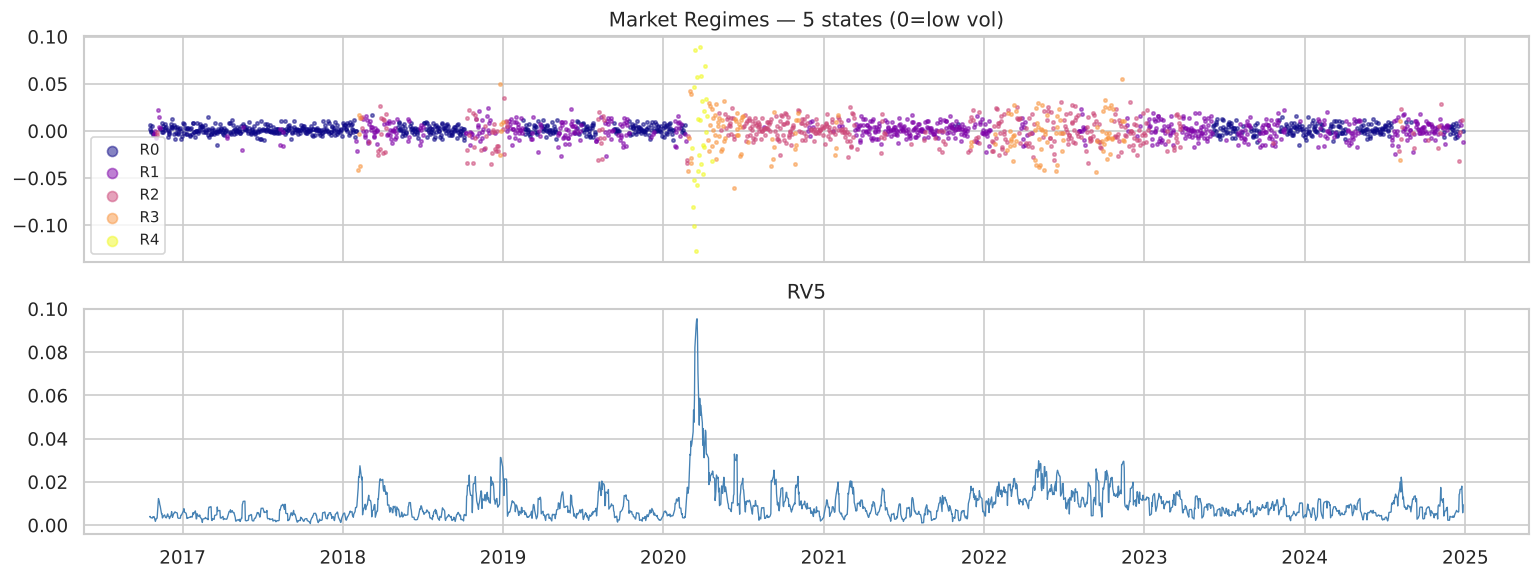

In [5]:
train_end = int(len(raw) * (1 - TEST_FRAC))
reg_feats = raw[['RV5', 'VIX']].values[:train_end]

# BIC selection on training data only
bic = {n: GaussianMixture(n, random_state=SEED, n_init=5).fit(reg_feats).bic(reg_feats)
       for n in range(2, 7)}
n_regimes = min(bic, key=bic.get)
print(f"Optimal GMM components: {n_regimes}  (BIC: {bic})")

gmm = GaussianMixture(n_regimes, random_state=SEED, n_init=5).fit(reg_feats)
labels_raw = gmm.predict(raw[['RV5', 'VIX']].values)

# Sort labels by mean RV5 so 0 = low vol, n_regimes-1 = high vol
label_map  = {old: new for new, old in
              enumerate(sorted(range(n_regimes),
                               key=lambda l: raw['RV5'].values[labels_raw == l].mean()))}
raw['Regime'] = np.vectorize(label_map.get)(labels_raw)

regime_cols = []
for r in range(n_regimes):
    col = f'Regime_{r}'
    raw[col] = (raw['Regime'] == r).astype(int)
    regime_cols.append(col)

# Visualise
cmap = plt.get_cmap('plasma', n_regimes)
fig, axes = plt.subplots(2, 1, figsize=(13, 5), sharex=True)
for r in range(n_regimes):
    m = raw['Regime'] == r
    axes[0].scatter(raw.index[m], raw['Log_Ret'].values[m],
                    s=4, alpha=0.5, color=cmap(r), label=f'R{r}')
axes[0].set_title(f'Market Regimes — {n_regimes} states (0=low vol)'); axes[0].legend(markerscale=3, fontsize=9)
axes[1].plot(raw['RV5'], lw=0.8, color='steelblue'); axes[1].set_title('RV5')
plt.tight_layout(); plt.show()

## 5. Feature Matrix & Train/Test Split

80/20 chronological split. **RobustScaler** (IQR-based) fitted on training data only — prevents March 2020 vol spike from compressing all other values (MinMaxScaler's failure mode).

In [6]:
FEATURE_COLS = [
    'Log_Ret', 'GARCH_Vol', 'VIX_Daily',
    'FracDiff_Close', 'VRP_Signal', 'Return_Mom', 'Vol_of_Vol',
    'Credit_Stress', 'Skewness', *regime_cols,
]
# Include Fear_Slope only if sufficiently populated
if raw['Fear_Slope'].notna().sum() > 100:
    FEATURE_COLS.append('Fear_Slope')
else:
    raw.drop(columns=['Fear_Slope'], inplace=True, errors='ignore')

TARGET_COL = 'Target_RV5'
X_all, y_all, sample_dates = build_lookback_windows(raw, FEATURE_COLS, TARGET_COL, LOOKBACK)

split_idx = int(len(X_all) * (1 - TEST_FRAC))
X_train_raw, X_test_raw = X_all[:split_idx],  X_all[split_idx:]
y_train,      y_test     = y_all[:split_idx],  y_all[split_idx:]
train_dates,  test_dates = sample_dates[:split_idx], sample_dates[split_idx:]

scaler  = RobustScaler()
X_train = scaler.fit_transform(X_train_raw)   # fit on train only — no leakage
X_test  = scaler.transform(X_test_raw)

# Log-vol target: vol is strictly positive and log-normally distributed
y_train_log = np.log(np.clip(y_train, 1e-8, None))
y_test_log  = np.log(np.clip(y_test,  1e-8, None))

joblib.dump(scaler, MODEL_DIR / 'feature_scaler.pkl')
print(f"Train: {X_train.shape}  ({train_dates[0].date()} → {train_dates[-1].date()})")
print(f"Test : {X_test.shape}   ({test_dates[0].date()}  → {test_dates[-1].date()})")

Train: (1633, 300)  (2016-11-15 → 2023-05-12)
Test : (409, 300)   (2023-05-15  → 2024-12-27)


## 6. Modeling

### 6a. GARCH Baseline (Out-of-Sample)

In [7]:
garch_test = raw['GARCH_Vol'].reindex(test_dates).values
mask = np.isfinite(garch_test) & np.isfinite(y_test)
garch_test_clean = garch_test[mask]

print('── GARCH(1,1)-t OOS Baseline ──────────────────────────────────────')
report('GARCH OOS', y_test[mask], garch_test_clean)

── GARCH(1,1)-t OOS Baseline ──────────────────────────────────────
GARCH OOS                       RMSE=0.002879  MAE=0.002239  QLIKE=0.0745  MAPE=40.96%


### 6b. XGBoost (log-vol target)

Predicting log(vol) ensures all forecasts are strictly positive after `exp()`. Walk-forward CV with 5-day embargo prevents leakage from the 5-day rolling RV target.

In [8]:
XGB_PARAMS = dict(n_estimators=300, learning_rate=0.04, max_depth=4,
                  subsample=0.8, colsample_bytree=0.8, reg_lambda=2,
                  random_state=SEED, tree_method='hist', verbosity=0)

model_xgb = xgb.XGBRegressor(**XGB_PARAMS)
model_xgb.fit(X_train, y_train_log)
y_pred_xgb = np.exp(model_xgb.predict(X_test))

print('── XGBoost OOS ──────────────────────────────────────────────────────')
report('XGBoost', y_test, y_pred_xgb)
joblib.dump(model_xgb, MODEL_DIR / 'xgb_base.pkl')

── XGBoost OOS ──────────────────────────────────────────────────────
XGBoost                         RMSE=0.002443  MAE=0.001816  QLIKE=0.0652  MAPE=26.94%


['../models/xgb_base.pkl']

### 6c. LightGBM GBDT

**Note:** DART replaced by standard GBDT. DART uses all trees at inference despite dropout during training, causing systematic underfitting on regression targets (observed MAPE ≈77%). GBDT with wider leaves (63 vs XGB's effective ~16) provides genuine model diversity.

In [9]:
model_lgbm = lgb.LGBMRegressor(
    boosting_type='gbdt', n_estimators=400, learning_rate=0.04,
    num_leaves=63, min_child_samples=20,
    subsample=0.8, colsample_bytree=0.8,
    reg_lambda=2, reg_alpha=0.1,
    random_state=SEED, verbose=-1,
)
model_lgbm.fit(X_train, y_train_log)
y_pred_lgbm = np.exp(model_lgbm.predict(X_test))

lgbm_mape = mape(y_test, y_pred_lgbm)
LGBM_OK = lgbm_mape < 0.60   # calibration guard for downstream ensemble inclusion
print('── LightGBM GBDT OOS ────────────────────────────────────────────────')
report('LGBM GBDT', y_test, y_pred_lgbm)
print(f"Calibration: {'✓ OK' if LGBM_OK else '✗ FAILED — excluded from ensemble'} (MAPE={lgbm_mape:.1%})")
joblib.dump(model_lgbm, MODEL_DIR / 'lgbm_gbdt.pkl')

── LightGBM GBDT OOS ────────────────────────────────────────────────
LGBM GBDT                       RMSE=0.002498  MAE=0.001844  QLIKE=0.0645  MAPE=27.87%
Calibration: ✓ OK (MAPE=27.9%)


['../models/lgbm_gbdt.pkl']

### 6d. Monotone-Constrained XGBoost (Entropy Model)

Encodes domain knowledge as hard constraints:
- `-1` (Log_Ret): leverage effect — negative returns disproportionately increase vol

This is the best interpretability–performance tradeoff in the suite.

In [10]:
constraint_map   = {'Log_Ret': -1}   # range features (GK, Parkinson, gap) need OHLC, not in open data
mono_constraints = get_monotone_constraints(FEATURE_COLS, LOOKBACK, constraint_map)

model_entropy = xgb.XGBRegressor(
    n_estimators=350, learning_rate=0.03, max_depth=4,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=3,
    monotone_constraints=mono_constraints,
    random_state=SEED, tree_method='hist', verbosity=0,
)
model_entropy.fit(X_train, y_train_log)
y_pred_entropy = np.exp(model_entropy.predict(X_test))

print('── Monotone-Constrained XGBoost (Entropy) OOS ───────────────────────')
report('Entropy', y_test, y_pred_entropy)
joblib.dump(model_entropy, MODEL_DIR / 'entropy_xgb.pkl')

── Monotone-Constrained XGBoost (Entropy) OOS ───────────────────────
Entropy                         RMSE=0.002677  MAE=0.002036  QLIKE=0.0778  MAPE=30.46%


['../models/entropy_xgb.pkl']

### 6e. Quantile Forecasts (10th / 50th / 90th Percentile)

Isotonic sort applied row-wise to prevent quantile crossing.

Empirical 80% interval coverage: 66.99%  (target ≈80%)


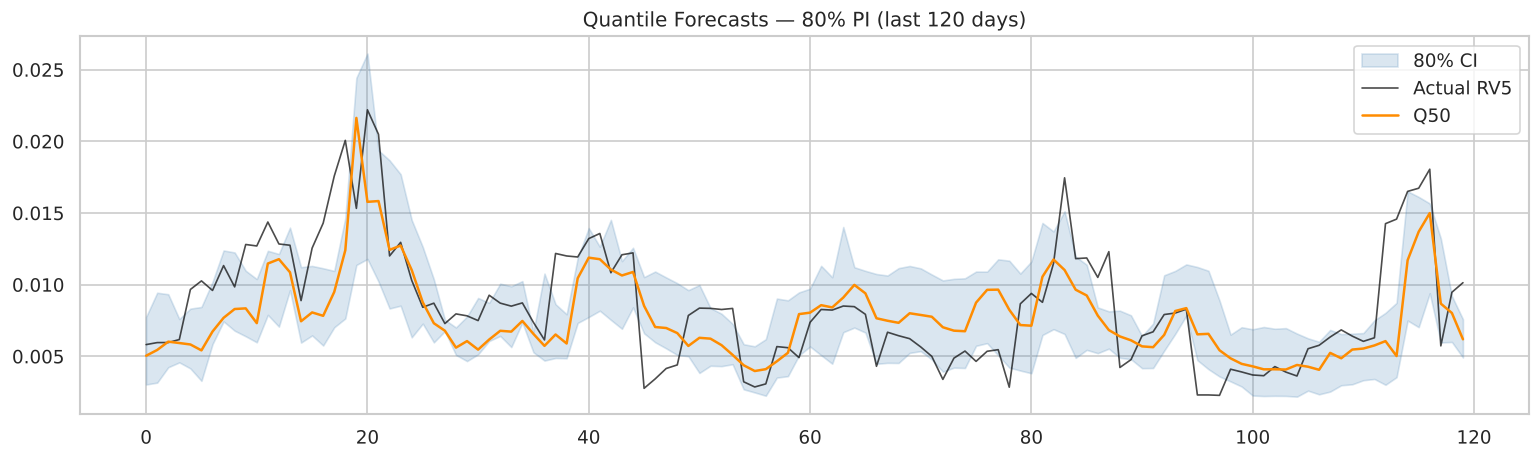

In [11]:
quantiles    = [0.1, 0.5, 0.9]
q_preds_log  = np.column_stack([
    xgb.XGBRegressor(objective='reg:quantileerror', quantile_alpha=q,
                     n_estimators=200, learning_rate=0.05, max_depth=4,
                     reg_lambda=2, random_state=SEED,
                     tree_method='hist', verbosity=0
                     ).fit(X_train, y_train_log).predict(X_test)
    for q in quantiles
])
# Isotonic sort per row: enforces q10 ≤ q50 ≤ q90
q_preds_exp  = np.exp(np.sort(q_preds_log, axis=1))
q_pred       = dict(zip(quantiles, q_preds_exp.T))

coverage_80 = np.mean((y_test >= q_pred[0.1]) & (y_test <= q_pred[0.9]))
print(f"Empirical 80% interval coverage: {coverage_80:.2%}  (target ≈80%)")

fig, ax = plt.subplots(figsize=(13, 4))
tail = 120
ax.fill_between(range(tail), q_pred[0.1][-tail:], q_pred[0.9][-tail:],
                alpha=0.2, color='steelblue', label='80% CI')
ax.plot(y_test[-tail:], color='black', lw=1.0, alpha=0.7, label='Actual RV5')
ax.plot(q_pred[0.5][-tail:], color='darkorange', lw=1.5, label='Q50')
ax.set_title('Quantile Forecasts — 80% PI (last 120 days)'); ax.legend()
plt.tight_layout(); plt.show()

### 6f. Calibrated Intervals (Conformalized Quantile Regression)

The raw 80% interval above is too narrow. Conformalized quantile regression (Romano, Patterson and Candes 2019) fixes this with a held-out calibration set: fit the 10% and 90% quantile models on the first 80% of the training window, measure how far the last 20% falls outside the band, and widen the band by that amount (in log-vol space). Coverage is then checked on the untouched test set.


In [12]:
from metrics import diebold_mariano  # used in 7c

n_cal   = int(len(X_train) * 0.2)
X_prop, X_cal = X_train[:-n_cal], X_train[-n_cal:]
y_prop, y_cal = y_train_log[:-n_cal], y_train_log[-n_cal:]

def _qmodel(q):
    return xgb.XGBRegressor(objective='reg:quantileerror', quantile_alpha=q,
                            n_estimators=200, learning_rate=0.05, max_depth=4,
                            reg_lambda=2, random_state=SEED,
                            tree_method='hist', verbosity=0).fit(X_prop, y_prop)

q_lo_m, q_hi_m = _qmodel(0.1), _qmodel(0.9)
lo_cal, hi_cal = np.sort(np.column_stack([q_lo_m.predict(X_cal), q_hi_m.predict(X_cal)]), axis=1).T
scores = np.maximum(lo_cal - y_cal, y_cal - hi_cal)          # CQR conformity score
level  = min(1.0, np.ceil((1 - 0.2) * (n_cal + 1)) / n_cal)  # finite-sample correction
q_hat  = np.quantile(scores, level, method='higher')

lo_t, hi_t = np.sort(np.column_stack([q_lo_m.predict(X_test), q_hi_m.predict(X_test)]), axis=1).T
raw_cov  = np.mean((y_test >= np.exp(lo_t)) & (y_test <= np.exp(hi_t)))
cqr_lo, cqr_hi = np.exp(lo_t - q_hat), np.exp(hi_t + q_hat)
cqr_cov  = np.mean((y_test >= cqr_lo) & (y_test <= cqr_hi))
print(f"Calibration window: {n_cal} days  |  widening q_hat = {q_hat:.4f} (log-vol)")
print(f"80% interval coverage on test  raw: {raw_cov:.2%}   conformal: {cqr_cov:.2%}")
print(f"Median interval width (vol units)  raw: {np.median(np.exp(hi_t) - np.exp(lo_t)):.5f}   conformal: {np.median(cqr_hi - cqr_lo):.5f}")


Calibration window: 326 days  |  widening q_hat = 0.1486 (log-vol)
80% interval coverage on test  raw: 66.99%   conformal: 81.66%
Median interval width (vol units)  raw: 0.00409   conformal: 0.00583


### 6f. Stacking Ensemble + Sovereign Prime (Huber Meta-Learner)

**Manual OOF stacking** (not `StackingRegressor`): sklearn's implementation calls `cross_val_predict`, which requires each sample to appear in *exactly one* validation fold — violated by `TimeSeriesSplit`'s expanding windows.

**Meta-learner input = base model OOF predictions only.** Passing raw features through to the meta-learner (common mistake) corrupts the two-stage structure and lets RidgeCV fit directly on 360+ raw features.

**Huber ε=1.35:** transitions from L2 to L1 at 1.35σ — dampens the influence of vol-spike days while remaining differentiable.

In [13]:
# ── Base models (only include LGBM if calibration passed) ─────────────────
base_specs = [
    ('xgb',     xgb.XGBRegressor(**XGB_PARAMS)),
    ('entropy', xgb.XGBRegressor(
        n_estimators=350, learning_rate=0.03, max_depth=4,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=3,
        monotone_constraints=mono_constraints,
        random_state=SEED, tree_method='hist', verbosity=0)),
]
if LGBM_OK:
    base_specs.append(('lgbm', lgb.LGBMRegressor(
        boosting_type='gbdt', n_estimators=400, learning_rate=0.04,
        num_leaves=63, min_child_samples=20,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=2, reg_alpha=0.1,
        random_state=SEED, verbose=-1)))

print(f"Stacking with: {[n for n, _ in base_specs]}")

tscv         = TimeSeriesSplit(n_splits=5)
n_train      = len(X_train)
oof_matrix   = np.zeros((n_train, len(base_specs)))

# OOF predictions on training set
for col_i, (name, est) in enumerate(base_specs):
    oof_col = np.zeros(n_train)
    for tr_idx, val_idx in tscv.split(X_train):
        tr_purged = tr_idx[:-EMBARGO] if len(tr_idx) > EMBARGO else tr_idx
        clone = type(est)(**est.get_params())
        clone.fit(X_train[tr_purged], y_train_log[tr_purged])
        oof_col[val_idx] = clone.predict(X_train[val_idx])
    oof_matrix[:, col_i] = oof_col
    print(f'  OOF: {name}')

# Fit base models on full training set
fitted_bases = []
for name, est in base_specs:
    est.fit(X_train, y_train_log)
    fitted_bases.append((name, est))

# RidgeCV meta-learner on OOF signals only — no raw feature passthrough
meta_ridge = RidgeCV(alphas=[0.01, 0.1, 1, 10, 100])
meta_ridge.fit(oof_matrix, y_train_log)
print(f'RidgeCV alpha: {meta_ridge.alpha_:.4f}')

test_base = np.column_stack([est.predict(X_test) for _, est in fitted_bases])
y_pred_stack_log = meta_ridge.predict(test_base)
y_pred_stack     = np.exp(y_pred_stack_log)

# ── Huber meta-learner (Sovereign Prime) ──────────────────────────────────
# Re-use OOF base predictions; convert from log-space to vol-space first
oof_vol = np.exp(oof_matrix)   # meta-learner operates in vol space

huber_meta = HuberRegressor(epsilon=1.35, max_iter=500)
huber_meta.fit(oof_vol, y_train)   # fit on vol-space target directly

test_base_vol = np.exp(test_base)
y_pred_sovereign = huber_meta.predict(test_base_vol)

print('\n── Stacking Ensemble & Sovereign Prime OOS ──────────────────────────')
report('Stacking (Ridge meta)',  y_test, y_pred_stack)
report('Sovereign Prime (Huber)', y_test, y_pred_sovereign)

joblib.dump({'bases': fitted_bases, 'meta_ridge': meta_ridge, 'huber_meta': huber_meta},
            MODEL_DIR / 'stack_model.pkl')

Stacking with: ['xgb', 'entropy', 'lgbm']


  OOF: xgb


  OOF: entropy


  OOF: lgbm


RidgeCV alpha: 0.1000

── Stacking Ensemble & Sovereign Prime OOS ──────────────────────────
Stacking (Ridge meta)           RMSE=0.003583  MAE=0.002896  QLIKE=0.1068  MAPE=52.21%
Sovereign Prime (Huber)         RMSE=0.003485  MAE=0.002859  QLIKE=0.1055  MAPE=55.25%


['../models/stack_model.pkl']

## 7. Evaluation

### 7a. Full Model Leaderboard

In [14]:
garch_aligned = garch_test_clean[:len(y_test)]

results = {
    'GARCH(1,1)-t':          garch_aligned,
    'XGBoost':               y_pred_xgb,
    'LightGBM GBDT':         y_pred_lgbm,
    'Entropy (monotone)':    y_pred_entropy,
    'Q50 (median)':          q_pred[0.5],
    'Stacking (Ridge meta)': y_pred_stack,
    'Sovereign Prime':       y_pred_sovereign,
}

print(f"{'Model':<28} {'RMSE':>10} {'MAE':>10} {'QLIKE':>10} {'MAPE':>8}")
print('─' * 70)
for name, yp in results.items():
    n = min(len(y_test), len(yp))
    print(f"{name:<28} {rmse(y_test[:n], yp[:n]):>10.6f} "
          f"{mae(y_test[:n], yp[:n]):>10.6f} "
          f"{qlike(y_test[:n], yp[:n]):>10.4f} "
          f"{mape(y_test[:n], yp[:n]):>8.2%}")

Model                              RMSE        MAE      QLIKE     MAPE
──────────────────────────────────────────────────────────────────────
GARCH(1,1)-t                   0.002879   0.002239     0.0745   40.96%
XGBoost                        0.002443   0.001816     0.0652   26.94%
LightGBM GBDT                  0.002498   0.001844     0.0645   27.87%
Entropy (monotone)             0.002677   0.002036     0.0778   30.46%
Q50 (median)                   0.002496   0.001881     0.0622   27.37%
Stacking (Ridge meta)          0.003583   0.002896     0.1068   52.21%
Sovereign Prime                0.003485   0.002859     0.1055   55.25%


### 7c. Diebold-Mariano Tests Against GARCH

Each model is tested against GARCH(1,1)-t on QLIKE and MSE. The RV5 target overlaps across five days, so the Newey-West bandwidth is 4 (h = 5); because residuals stay autocorrelated beyond that, a 21-lag bandwidth (h = 22) is shown as a robustness check. A positive statistic means the model is more accurate than GARCH.


In [15]:
rows = []
for name, yp in results.items():
    if name.startswith('GARCH'):
        continue
    n = min(len(y_test), len(yp), len(garch_aligned))
    for loss in ('qlike', 'mse'):
        stat, p = diebold_mariano(y_test[:n], garch_aligned[:n], yp[:n], loss=loss, h=5)
        stat22, p22 = diebold_mariano(y_test[:n], garch_aligned[:n], yp[:n], loss=loss, h=22)
        rows.append({'Model': name, 'Loss': loss.upper(), 'DM stat (h=5)': round(stat, 3),
                     'p (h=5)': round(p, 4), 'DM stat (h=22)': round(stat22, 3), 'p (h=22)': round(p22, 4)})
dm_table = pd.DataFrame(rows)
print(dm_table.to_string(index=False))


                Model  Loss  DM stat (h=5)  p (h=5)  DM stat (h=22)  p (h=22)
              XGBoost QLIKE          1.050   0.2936           1.209    0.2266
              XGBoost   MSE          2.613   0.0090           2.725    0.0064
        LightGBM GBDT QLIKE          1.201   0.2296           1.474    0.1404
        LightGBM GBDT   MSE          2.333   0.0196           2.782    0.0054
   Entropy (monotone) QLIKE         -0.345   0.7302          -0.368    0.7125
   Entropy (monotone)   MSE          1.167   0.2430           1.174    0.2406
         Q50 (median) QLIKE          1.499   0.1339           1.707    0.0878
         Q50 (median)   MSE          2.172   0.0298           2.360    0.0183
Stacking (Ridge meta) QLIKE         -3.539   0.0004          -2.965    0.0030
Stacking (Ridge meta)   MSE         -2.944   0.0032          -2.906    0.0037
      Sovereign Prime QLIKE         -3.771   0.0002          -2.937    0.0033
      Sovereign Prime   MSE         -3.035   0.0024          -2.

### 7b. Residual Diagnostics

Heteroscedasticity (Spearman |resid|~pred): ρ=-0.094  p=0.0567
       lb_stat      lb_pvalue
5   567.480799  2.143630e-120
10  632.415519  1.985660e-129


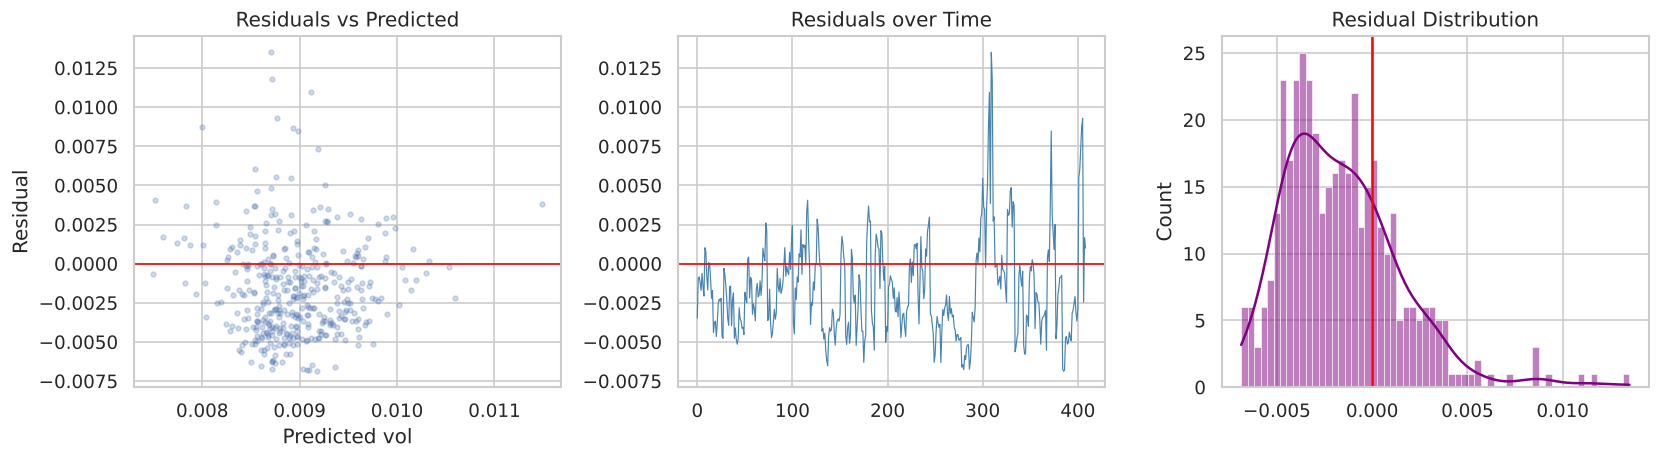

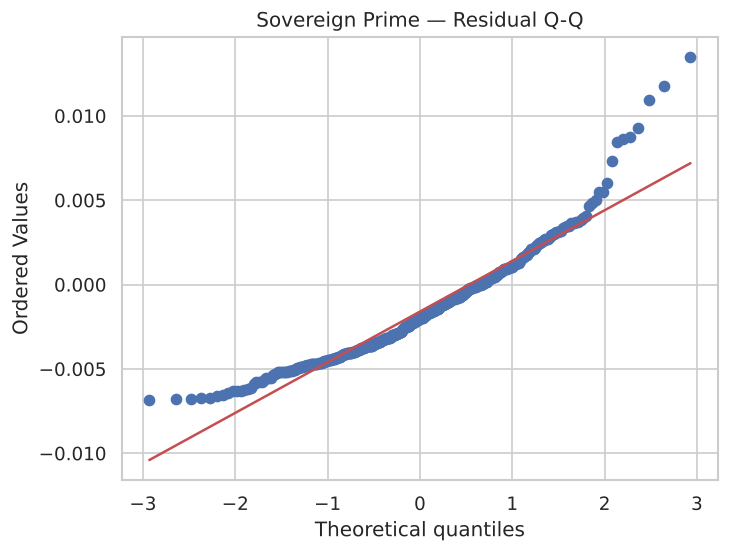

In [16]:
from scipy.stats import spearmanr

residuals = y_test - y_pred_sovereign

sp_rho, sp_p = spearmanr(y_pred_sovereign, np.abs(residuals))
lb = acorr_ljungbox(residuals, lags=[5, 10], return_df=True)

print(f"Heteroscedasticity (Spearman |resid|~pred): ρ={sp_rho:.3f}  p={sp_p:.4f}")
print(lb.to_string())

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].scatter(y_pred_sovereign, residuals, alpha=0.25, s=8)
axes[0].axhline(0, color='red', lw=1)
axes[0].set(xlabel='Predicted vol', ylabel='Residual', title='Residuals vs Predicted')

axes[1].plot(residuals, lw=0.7, color='steelblue')
axes[1].axhline(0, color='red', lw=1); axes[1].set_title('Residuals over Time')

sns.histplot(residuals, kde=True, bins=60, color='purple', ax=axes[2])
axes[2].axvline(0, color='red', lw=1.5); axes[2].set_title('Residual Distribution')
plt.tight_layout(); plt.show()

stats.probplot(residuals, plot=plt); plt.title('Sovereign Prime — Residual Q-Q'); plt.show()

### 7c. Forecast Comparison Plot

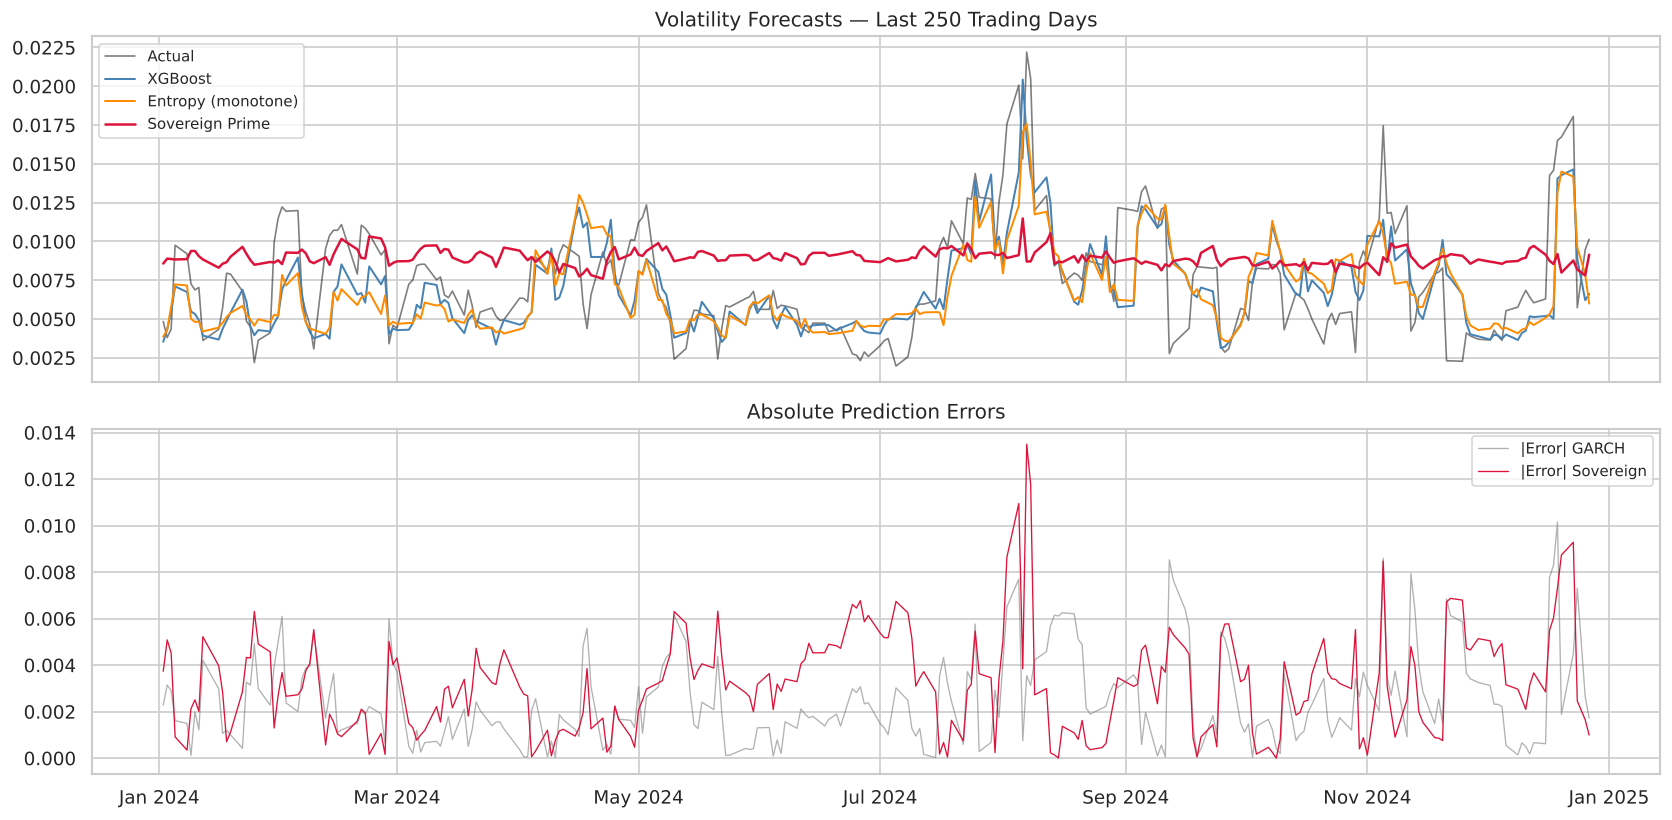

In [17]:
n_plot = 250
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(test_dates[-n_plot:], y_test[-n_plot:], color='black', lw=1.0, alpha=0.5, label='Actual')
axes[0].plot(test_dates[-n_plot:], y_pred_xgb[-n_plot:],      color='steelblue',  lw=1.2, label='XGBoost')
axes[0].plot(test_dates[-n_plot:], y_pred_entropy[-n_plot:],   color='darkorange',  lw=1.2, label='Entropy (monotone)')
axes[0].plot(test_dates[-n_plot:], y_pred_sovereign[-n_plot:], color='crimson',     lw=1.5, label='Sovereign Prime')
axes[0].set_title('Volatility Forecasts — Last 250 Trading Days')
axes[0].legend(fontsize=9)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

axes[1].plot(test_dates[-n_plot:],
             np.abs(y_test[-n_plot:] - garch_aligned[-n_plot:]),
             color='gray', lw=0.8, alpha=0.6, label='|Error| GARCH')
axes[1].plot(test_dates[-n_plot:],
             np.abs(y_test[-n_plot:] - y_pred_sovereign[-n_plot:]),
             color='crimson', lw=0.8, label='|Error| Sovereign')
axes[1].set_title('Absolute Prediction Errors'); axes[1].legend(fontsize=9)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.tight_layout(); plt.show()